In [1]:
from scipy.stats import norm
from nautilus import Prior

prior = Prior()
prior.add_parameter('a', dist=(-5, +5))
prior.add_parameter('b', dist=(-5, +5))
prior.add_parameter('c', dist=norm(loc=0, scale=2.0))

In [2]:
import numpy as np
from scipy.stats import multivariate_normal

def likelihood(param_dict):
    x = np.array([param_dict['a'], param_dict['b'], param_dict['c']])
    return multivariate_normal.logpdf(
        x, mean=np.zeros(3), cov=[[1, 0, 0.90], [0, 1, 0], [0.90, 0, 1]])

In [5]:
from nautilus import Sampler

sampler = Sampler(prior, likelihood, n_live=10000)
sampler.run(verbose=True)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 13     | 1        | 4        | 138500   | N/A    | 62368 | -6.33    


np.True_

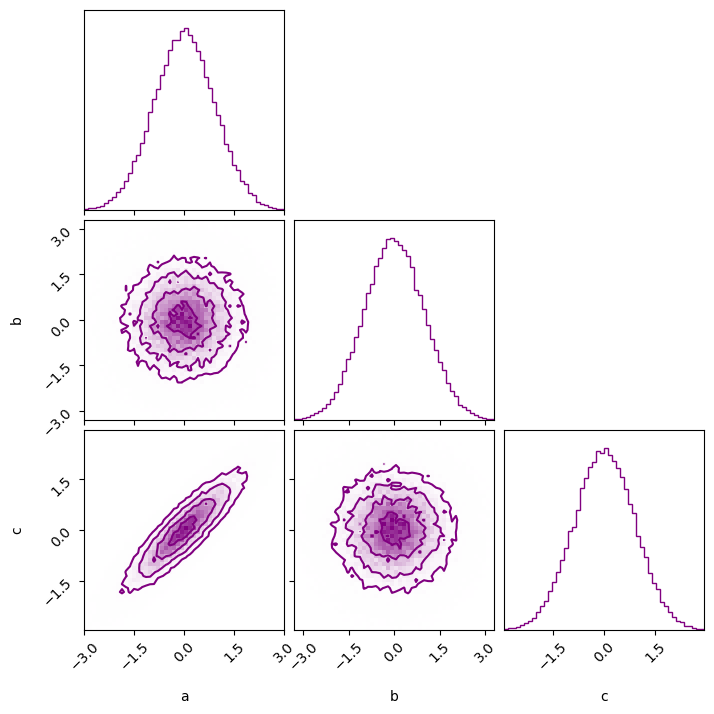

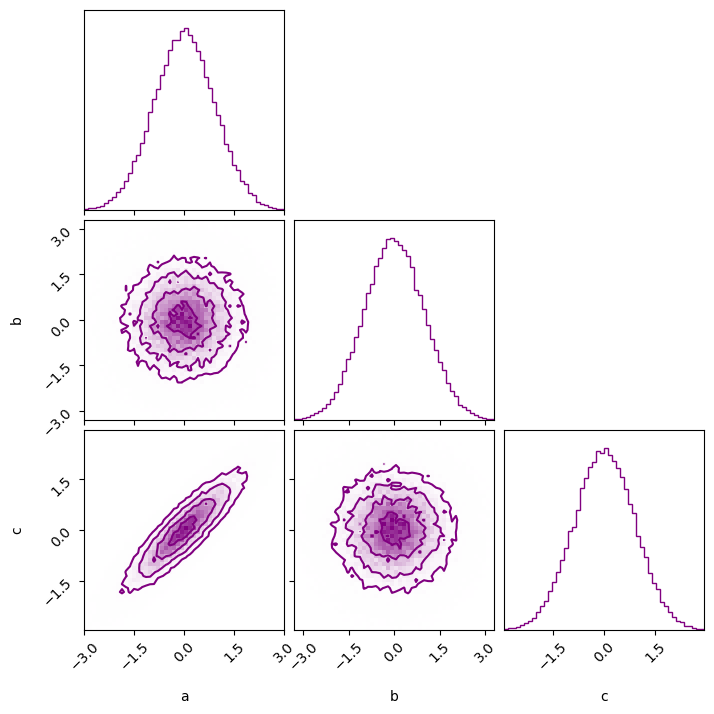

In [10]:
import corner
import matplotlib.pyplot as plt

points, log_w, log_l = sampler.posterior()
corner.corner(
    points, weights=np.exp(log_w), bins=50, labels=prior.keys, color='purple',
    plot_datapoints=False, range=np.repeat(0.999, len(prior.keys)))